In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [3]:
train_df  = pd.read_csv("../data/raw/mitbih_train.csv",header=None)
train_df.head()

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,0.977941,0.926471,0.681373,0.245098,0.154412,0.191176,0.151961,0.085784,0.058824,0.049020,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
test_df  = pd.read_csv("../data/raw/mitbih_test.csv",header=None)
test_df.head()

,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,1.000000,0.758264,0.111570,0.000000,0.080579,0.078512,0.066116,0.049587,0.047521,0.035124,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.908425,0.783883,0.531136,0.362637,0.366300,0.344322,0.333333,0.307692,0.296703,0.300366,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.730088,0.212389,0.000000,0.119469,0.101770,0.101770,0.110619,0.123894,0.115044,0.132743,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.000000,0.910417,0.681250,0.472917,0.229167,0.068750,0.000000,0.004167,0.014583,0.054167,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.570470,0.399329,0.238255,0.147651,0.000000,0.003356,0.040268,0.080537,0.070470,0.090604,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
print("Missing values:", train_df.isnull().sum().sum())
print("Duplicate rows:", train_df.duplicated().sum())
print("Infinite values:", np.isinf(train_df.to_numpy()).sum())

Missing values: 0
Duplicate rows: 0
Infinite values: 0


In [6]:
print("Missing values:", test_df.isnull().sum().sum())
print("Duplicate rows:", test_df.duplicated().sum())
print("Infinite values:", np.isinf(test_df.to_numpy()).sum())

Missing values: 0
Duplicate rows: 0
Infinite values: 0


In [7]:
class_counts = train_df[187].value_counts().sort_index()

print(class_counts)

187
0.0    72471
1.0     2223
2.0     5788
3.0      641
4.0     6431
Name: count, dtype: int64


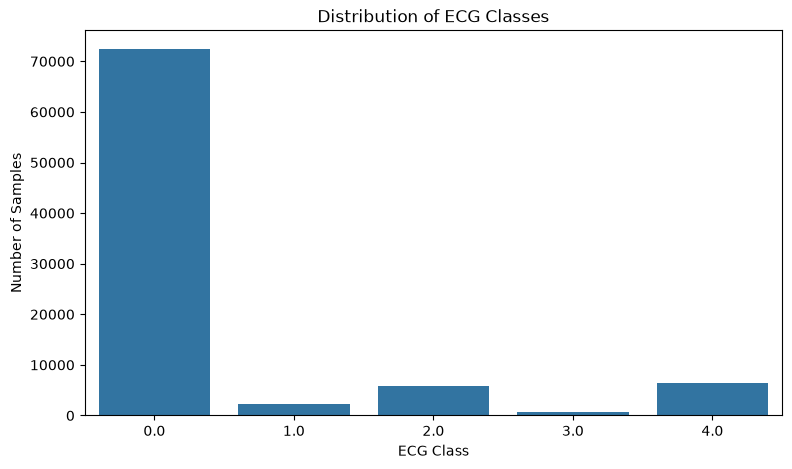

In [8]:
plt.figure(figsize=(9, 5))

sns.barplot(x=class_counts.index,y=class_counts.values
)

plt.xlabel("ECG Class")
plt.ylabel("Number of Samples")
plt.title("Distribution of ECG Classes")
plt.show()

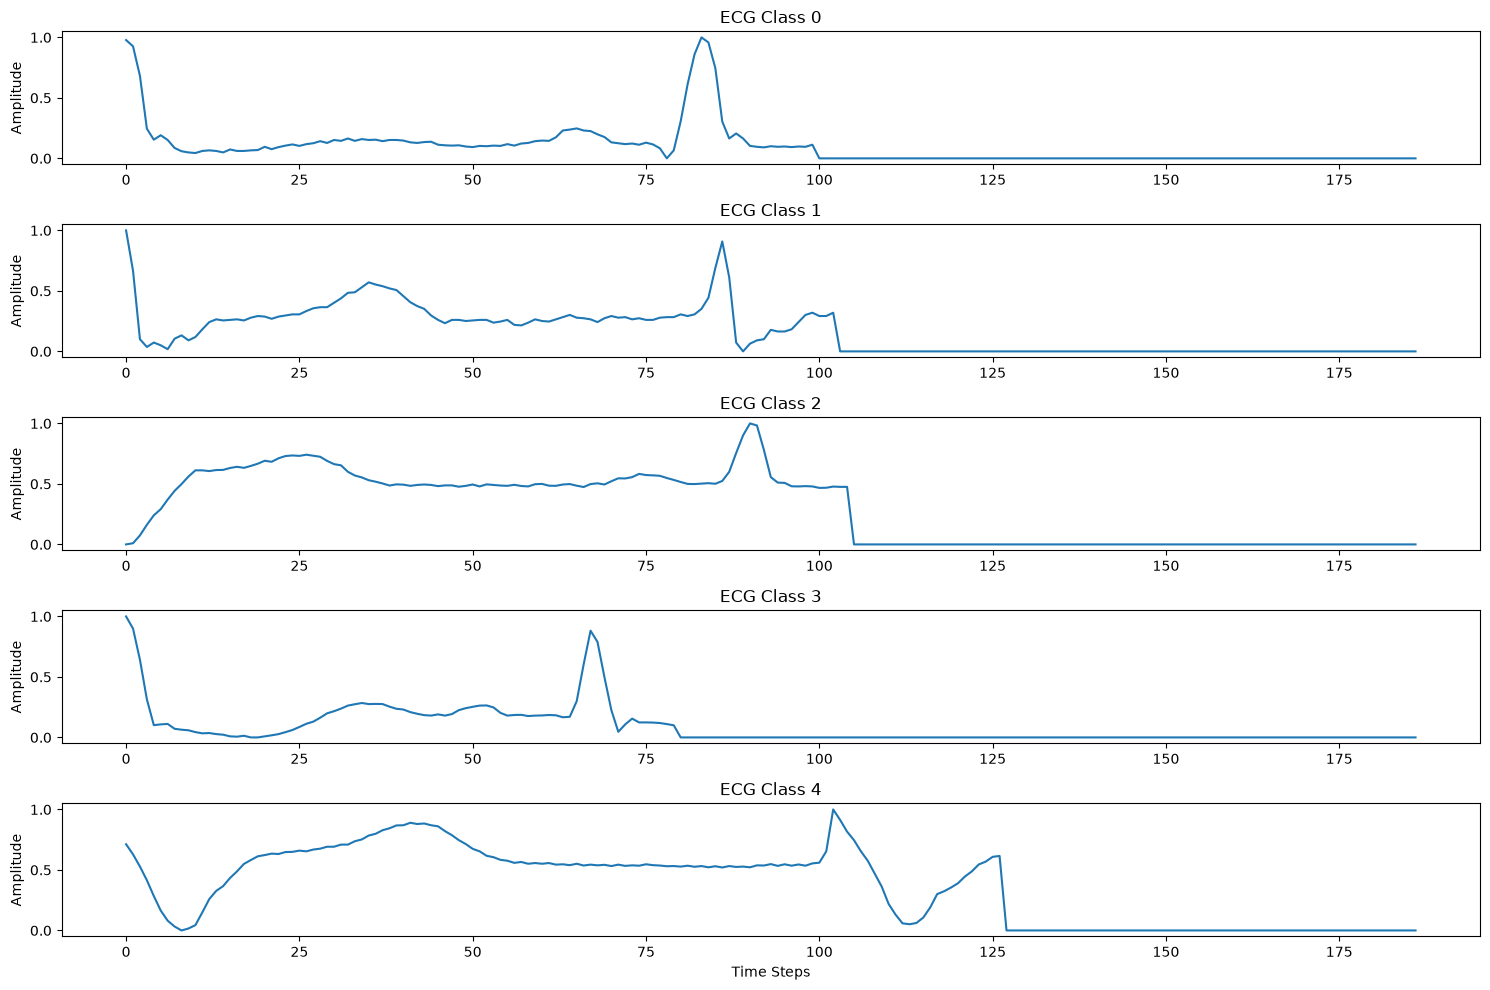

In [9]:
plt.figure(figsize=(15, 10))

for i in range(5):
    signal = train_df[train_df[187] == i].iloc[0, :-1].values

    plt.subplot(5, 1, i + 1)
    plt.plot(signal)
    plt.title(f"ECG Class {i}")
    plt.ylabel("Amplitude")

plt.xlabel("Time Steps")
plt.tight_layout()
plt.show()

In [10]:
class_counts = train_df[187].value_counts().sort_index()

class_percentage = (class_counts / len(train_df)) * 100

print(class_percentage)

187
0.0    82.772917
1.0     2.539005
2.0     6.610777
3.0     0.732120
4.0     7.345181
Name: count, dtype: float64


In [11]:
signals = train_df.iloc[:, :-1]

print("Minimum:", signals.min().min())
print("Maximum:", signals.max().max())
print("Mean:", signals.mean().mean())
print("Standard deviation:", signals.std().mean())

Minimum: 0.0
Maximum: 1.0
Mean: 0.17428295254906376
Standard deviation: 0.17542948924983826


In [12]:
X = train_df.iloc[:,:-1]
y = train_df.iloc[:,-1]

In [13]:
print(X.shape)
print(y.shape)

(87554, 187)
(87554,)


In [14]:
train_X,test_X,train_y,test_y = train_test_split(X,y,test_size=0.15,stratify=y,random_state=42)

In [15]:
scaler = StandardScaler()
scaled_train_X = scaler.fit_transform(train_X)
scaled_test_X = scaler.transform(test_X)

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

In [17]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(train_X, train_y)
dummy_pred = dummy.predict(test_X)

In [18]:
print("Accuracy:", accuracy_score(test_y, dummy_pred))
print("Macro F1:", f1_score(test_y, dummy_pred, average="macro"))
print("Balanced Accuracy:", balanced_accuracy_score(test_y, dummy_pred))

Accuracy: 0.8276991015684483
Macro F1: 0.18114559466777755
Balanced Accuracy: 0.2


In [19]:
print("Dummy Classifier")
print(classification_report(test_y, dummy_pred, digits=3))

Dummy Classifier
              precision    recall  f1-score   support

         0.0      0.828     1.000     0.906     10871
         1.0      0.000     0.000     0.000       334
         2.0      0.000     0.000     0.000       868
         3.0      0.000     0.000     0.000        96
         4.0      0.000     0.000     0.000       965

    accuracy                          0.828     13134
   macro avg      0.166     0.200     0.181     13134
weighted avg      0.685     0.828     0.750     13134



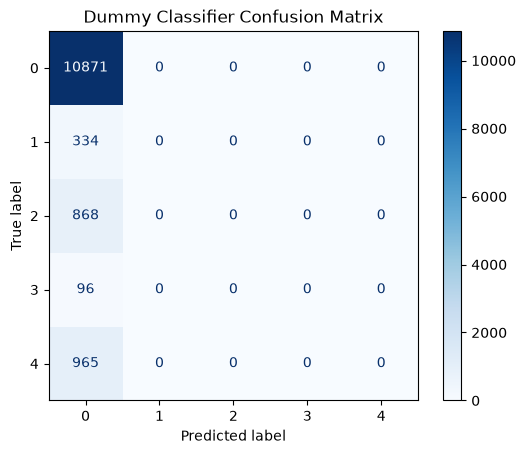

In [20]:
cm = confusion_matrix(test_y, dummy_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Dummy Classifier Confusion Matrix")
plt.show()

In [21]:
params = {"C":[0.01,0.1,1,10],"solver":["lbfgs"],"max_iter":[1000,2000],"class_weight":["balanced"]}

random_search = RandomizedSearchCV(LogisticRegression(),params,cv=5,n_iter=10,n_jobs=-1,random_state=42) 
random_search.fit(scaled_train_X,train_y)
best_lr_model = random_search.best_estimator_
y_pred = best_lr_model.predict(scaled_test_X)

In [22]:
print("Accuracy:", accuracy_score(test_y, y_pred))
print("Macro F1:", f1_score(test_y, y_pred, average="macro"))
print("Balanced Accuracy:", balanced_accuracy_score(test_y, y_pred))

Accuracy: 0.6771737475255063
Macro F1: 0.4858273490958817
Balanced Accuracy: 0.779636089367639


In [23]:
print("Logistic Regression")
print(classification_report(test_y, y_pred, digits=3))

Logistic Regression
              precision    recall  f1-score   support

         0.0      0.976     0.646     0.778     10871
         1.0      0.157     0.707     0.256       334
         2.0      0.300     0.742     0.427       868
         3.0      0.080     0.865     0.146        96
         4.0      0.731     0.939     0.822       965

    accuracy                          0.677     13134
   macro avg      0.449     0.780     0.486     13134
weighted avg      0.886     0.677     0.740     13134



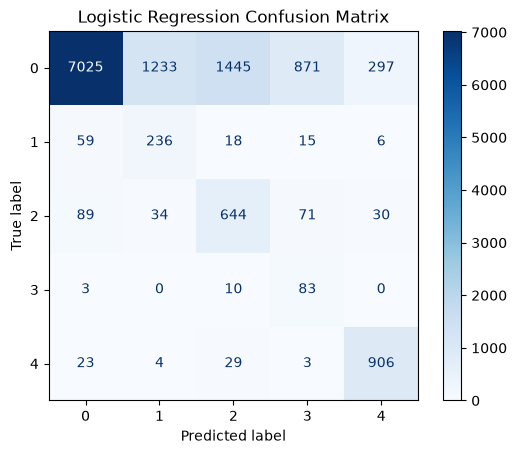

In [24]:
cm = confusion_matrix(test_y, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [27]:
params = {"n_estimators":[100,200,300],"max_depth":[10,20,None],"min_samples_split":[2,5],"min_samples_leaf":[1,2],"max_features":["sqrt","log2"],"class_weight":["balanced"]}

random_search = RandomizedSearchCV(RandomForestClassifier(),params,cv=5,n_iter=10,n_jobs=-1,random_state=42) 
random_search.fit(train_X,train_y)
best_rf_model = random_search.best_estimator_
rf_pred = best_rf_model.predict(test_X)

In [28]:
print("Accuracy:", accuracy_score(test_y, rf_pred))
print("Macro F1:", f1_score(test_y, rf_pred, average="macro"))
print("Balanced Accuracy:", balanced_accuracy_score(test_y, rf_pred))

Accuracy: 0.9797472209532511
Macro F1: 0.8997546984302762
Balanced Accuracy: 0.8715789517598516


In [29]:
print("Random Forest")
print(classification_report(test_y, rf_pred, digits=3))

Random Forest
              precision    recall  f1-score   support

         0.0      0.985     0.993     0.989     10871
         1.0      0.900     0.754     0.821       334
         2.0      0.935     0.934     0.935       868
         3.0      0.859     0.698     0.770        96
         4.0      0.990     0.978     0.984       965

    accuracy                          0.980     13134
   macro avg      0.934     0.872     0.900     13134
weighted avg      0.979     0.980     0.979     13134



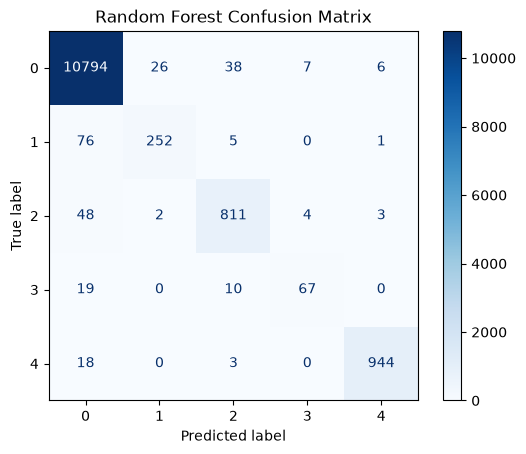

In [30]:
cm = confusion_matrix(test_y, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2, 3, 4]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [31]:
results = []

models = {
    "Dummy Classifier": dummy_pred,
    "Logistic Regression": y_pred,
    "Random Forest": rf_pred
}

for name, predictions in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(test_y, predictions),
        "Macro F1": f1_score(test_y, predictions, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(test_y, predictions)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Macro F1,Balanced Accuracy
0,Dummy Classifier,0.827699,0.181146,0.200000
1,Logistic Regression,0.677174,0.485827,0.779636
2,Random Forest,0.979747,0.899755,0.871579


In [32]:
from pathlib import Path
import json

metrics_dir = Path("../results/metrics")
figures_dir = Path("../results/figures")
metrics_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(metrics_dir / "baselines.csv", index=False)

In [33]:
class_names = ["N", "S", "V", "F", "Q"]
models = {
    "dummy": dummy_pred,
    "logistic_regression": y_pred,
    "random_forest": rf_pred,
}

for name, preds in models.items():
    report = classification_report(
        test_y, preds, target_names=class_names, digits=3, output_dict=True
    )
    pd.DataFrame(report).T.to_csv(metrics_dir / f"per_class_{name}.csv")

In [34]:
for name, preds in models.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        test_y, preds, display_labels=class_names,
        normalize="true", cmap="Blues", ax=ax
    )
    ax.set_title(f"{name} (row-normalized)")
    fig.savefig(figures_dir / f"confusion_{name}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

In [35]:
best_params = {
    "logistic_regression": best_lr_model.get_params(),
    "random_forest": best_rf_model.get_params(),
}
with open(metrics_dir / "baseline_best_params.json", "w") as f:
    json.dump(best_params, f, indent=2, default=str)

In [36]:
import joblib
Path("../models").mkdir(exist_ok=True)
joblib.dump(best_lr_model, "../models/baseline_lr.joblib")
joblib.dump(best_rf_model, "../models/baseline_rf.joblib")

['../models/baseline_rf.joblib']